In [1]:
import sys, os, warnings, subprocess
subprocess.run(["pip", "install", ".", "--quiet"], check=True, cwd="/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales")
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import pandas as pd
import scipy as sp

import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 8})
plt.rcParams["svg.fonttype"] = "none"
import seaborn as sns

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])
sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/nctpy/src'])

from snaplab_tools.plotting.plotting import brain_scatter_plot
from snaplab_tools.plotting.utils import get_my_colors
from snaplab_tools.utils import get_schaefer_system_mask

  DEPRECATION: Building 'src' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'src'. Discussion can be found at https://github.com/pypa/pip/issues/6334


# Load data

In [2]:
# ── Dataset selector ──────────────────────────────────────────────────────────
dataset = 'HCP-D'   # 'HCP-D' | 'HCP-YA'

_cfg = {
    'HCP-D': {
        'rest_task':  'rfMRIREST1PA',
        'task_name':  'tfMRICARITPA',
        'task_label': 'CARIT',
    },
    'HCP-YA': {
        'rest_task':  'rfMRIREST1LR',
        'task_name':  'tfMRIWMLR',
        'task_label': 'WM',
    },
}[dataset]

rest_task  = _cfg['rest_task']
task_name  = _cfg['task_name']
task_label = _cfg['task_label']

# ── Paths ─────────────────────────────────────────────────────────────────────
projdir = '/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales'
nct_dir = os.path.join(projdir, 'data', 'nct', dataset)
con_dir = os.path.join(projdir, 'data', 'task_contrasts', dataset)
out_dir = os.path.join(projdir, 'results', dataset, 'nct')
os.makedirs(out_dir, exist_ok=True)

seg       = 'Schaefer4007'
n_parcels = 400
if dataset == 'HCP-YA':
    k_rest    = 7
    k_task    = 7
elif dataset == 'HCP-D':
    k_rest    = 5
    k_task    = 5

# k-means cluster files
kmeans_files = {
    'REST (k-means)':           f'{dataset}_{seg}_task-{rest_task}_fmri_clusters_k-{k_rest}.npy',
    f'{task_label} (k-means)':  f'{dataset}_{seg}_task-{task_name}_fmri_clusters_k-{k_task}.npy',
}

# task contrast file
contrast_file = f'{dataset}_{seg}_task-{task_name}_data-task_contrasts.npy'


In [3]:
parc_centroids = pd.read_csv(
    os.path.join(projdir, 'data', 'supporting_data',
                 'Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.Centroid_RAS.csv'),
    index_col=1
)
parc_centroids.drop(columns=['ROI Label'], inplace=True)
parc_centroids.head()

,R,A,S
ROI Name,,,
7Networks_LH_Vis_1,-33,-42,-21
7Networks_LH_Vis_2,-30,-33,-18
7Networks_LH_Vis_3,-36,-62,-17
7Networks_LH_Vis_4,-24,-55,-8
7Networks_LH_Vis_5,-23,-73,-10


# Elbow plot — choosing k

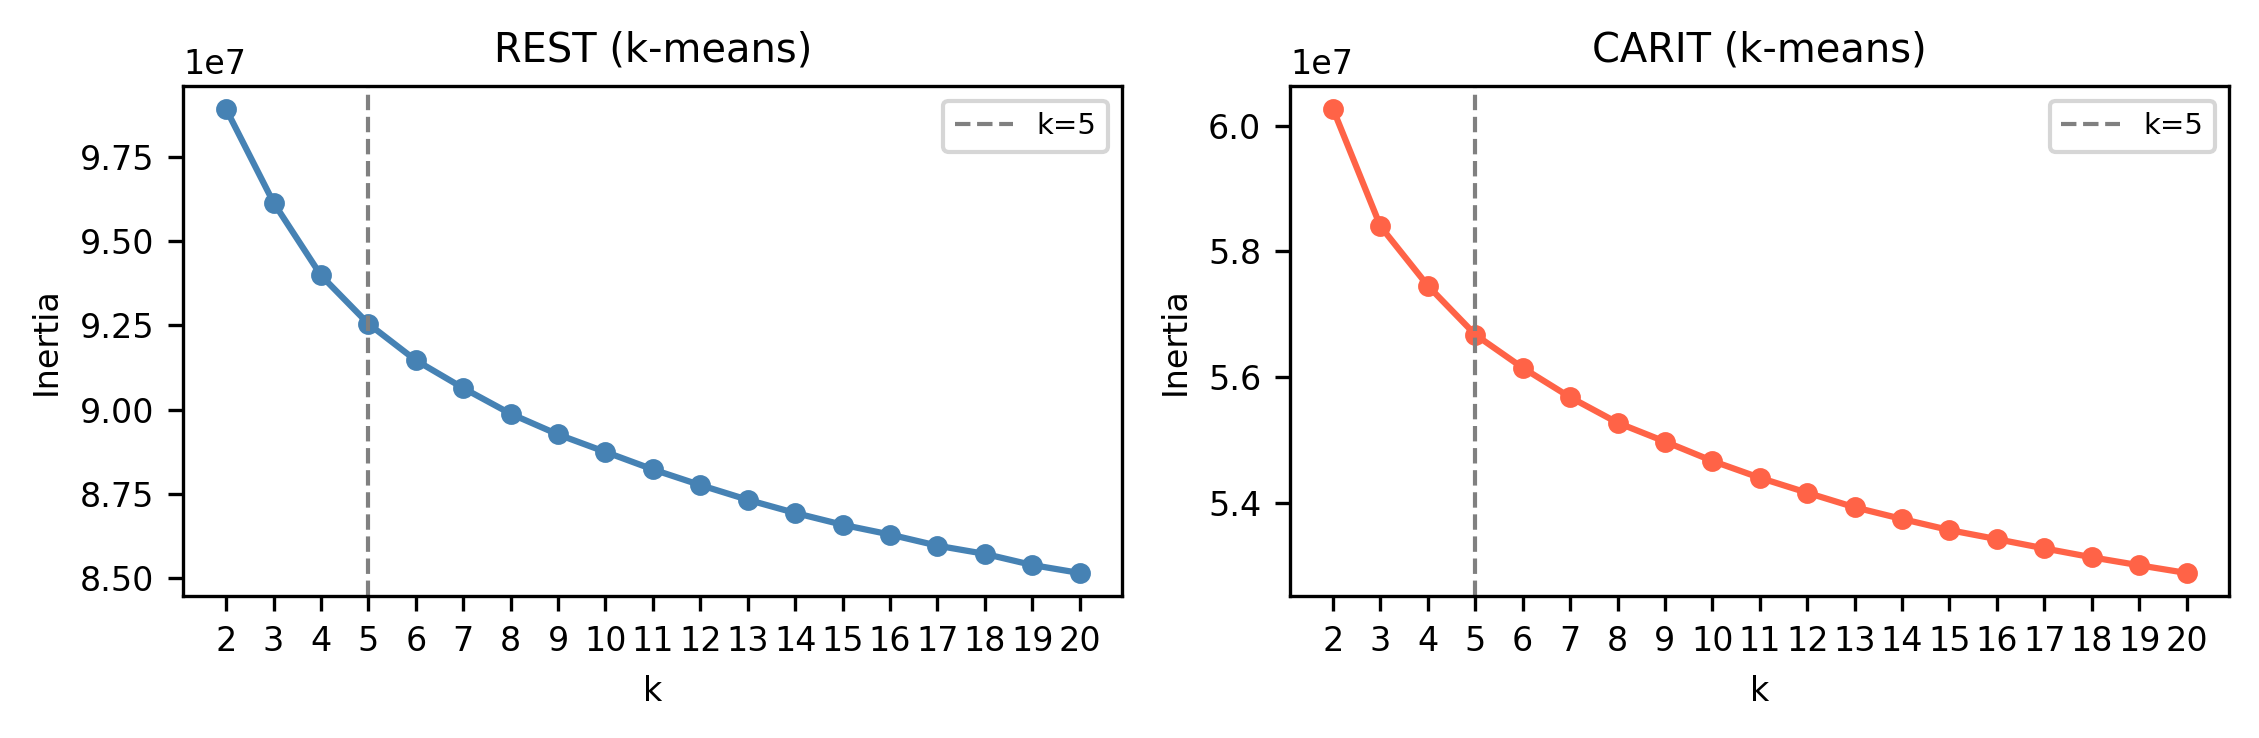

In [4]:
k_range = np.arange(2, 21)

inertia_rest = [
    np.load(os.path.join(nct_dir, f'{dataset}_{seg}_task-{rest_task}_fmri_clusters_k-{k_i}.npy'),
            allow_pickle=True).item()['inertia']
    for k_i in k_range
]
inertia_task = [
    np.load(os.path.join(nct_dir, f'{dataset}_{seg}_task-{task_name}_fmri_clusters_k-{k_i}.npy'),
            allow_pickle=True).item()['inertia']
    for k_i in k_range
]

fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.5), dpi=300)

for ax, inertia, label, k_sel, color in zip(
    axes,
    [inertia_rest, inertia_task],
    ['REST (k-means)', f'{task_label} (k-means)'],
    [k_rest, k_task],
    ['steelblue', 'tomato'],
):
    ax.plot(k_range, inertia, marker='o', ms=4, color=color)
    ax.axvline(k_sel, color='gray', linestyle='--', linewidth=1, label=f'k={k_sel}')
    ax.set_xlabel('k')
    ax.set_ylabel('Inertia')
    ax.set_title(label)
    ax.set_xticks(k_range)
    ax.legend(fontsize=7)

fig.tight_layout()
fig.savefig(os.path.join(out_dir, 'elbow_plot.png'), dpi=300, bbox_inches='tight', pad_inches=0.01)
plt.show()


In [5]:
# ── 1. k-means cluster solutions ─────────────────────────────────────────────
clusters = {}
for label, fname in kmeans_files.items():
    clusters[label] = np.load(os.path.join(nct_dir, fname), allow_pickle=True).item()
    print(label, '-> keys:', list(clusters[label].keys()))
    print('  centroids:', clusters[label]['centroids'].shape)
    print('  labels:   ', clusters[label]['labels'].shape)
    print('  var expl: ', round(float(clusters[label]['variance_explained']) * 100, 2), '%')

# ── 2. Task contrasts (group-averaged beta maps) ──────────────────────────────
contrast_data = np.load(os.path.join(con_dir, contrast_file), allow_pickle=True).item()

# Collect per-condition beta maps across subjects, z-scoring each subject's
# map across parcels so contrasts are on the same scale as k-means centroids
contrast_names = list(next(v for v in contrast_data.values() if v is not None).keys())
contrast_stack  = {c: [] for c in contrast_names}
for scan_key, sub_contrasts in contrast_data.items():
    if sub_contrasts is None:
        continue
    for cname, bmap in sub_contrasts.items():
        mu, sigma = np.nanmean(bmap), np.nanstd(bmap)
        if sigma > 0:
            contrast_stack[cname].append((bmap - mu) / sigma)

# Group average: (n_conditions, n_parcels)
contrast_centroids = np.vstack([
    np.nanmean(np.stack(contrast_stack[c], axis=0), axis=0)[np.newaxis, :]
    for c in contrast_names
])
print(f'\n{task_label} contrasts: {len(contrast_names)} conditions x {n_parcels} parcels')
print('  conditions:', contrast_names)
print('  centroids shape:', contrast_centroids.shape)

# Bundle alongside the k-means sets for consistent downstream handling
clusters[f'{task_label} (contrasts)'] = {'centroids': contrast_centroids, 'condition_names': contrast_names}


REST (k-means) -> keys: ['centroids', 'labels', 'inertia', 'centroid_subj_frac', 'variance_explained']
  centroids: (5, 400)
  labels:    (263856,)
  var expl:  58.91 %
CARIT (k-means) -> keys: ['centroids', 'labels', 'inertia', 'centroid_subj_frac', 'variance_explained']
  centroids: (5, 400)
  labels:    (160080,)
  var expl:  58.91 %

CARIT contrasts: 6 conditions x 400 parcels
  conditions: ['go', 'miss', 'nogoCRLose', 'nogoCRWin', 'nogoFALose', 'nogoFAWin']
  centroids shape: (6, 400)


# Brain state maps

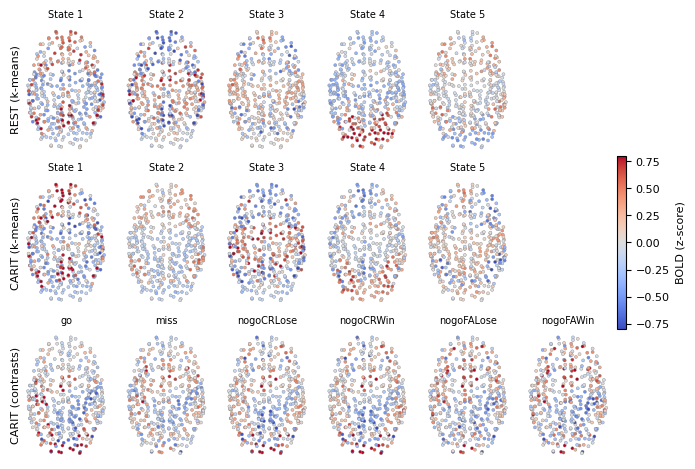

In [6]:
import matplotlib as mpl

fig_height = 1.25
row_labels = list(clusters.keys())          # 3 rows
n_rows = len(row_labels)
# widest row drives the number of columns
n_cols = max(clusters[l]['centroids'].shape[0] for l in row_labels)

vmin, vmax = -0.8, 0.8

fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_height * 1.2 * n_cols, fig_height * n_rows * 1.5))

for row_idx, label in enumerate(row_labels):
    centroids  = clusters[label]['centroids']
    n_states   = centroids.shape[0]
    # per-row column labels: use condition names for the contrasts row
    if 'contrasts' in label:
        col_titles = clusters[label]['condition_names']
    else:
        col_titles = [f'State {i + 1}' for i in range(n_states)]

    for state_idx in range(n_cols):
        ax = axes[row_idx, state_idx]
        if state_idx < n_states:
            brain_scatter_plot(
                parcel_coords=parc_centroids,
                node_data=centroids[state_idx, :],
                vmin=vmin, vmax=vmax,
                cmap='coolwarm',
                add_colorbar=False,
                ax=ax,
            )
            ax.set_title(col_titles[state_idx], fontsize=7)
        else:
            ax.set_visible(False)

    axes[row_idx, 0].text(-0.05, 0.5, label, transform=axes[row_idx, 0].transAxes,
                          rotation=90, va='center', ha='right', fontsize=8)

sm = mpl.cm.ScalarMappable(cmap='coolwarm', norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])
fig.colorbar(sm, ax=axes, shrink=0.4, aspect=20, pad=0.01, label='BOLD (z-score)')

fig.savefig(os.path.join(out_dir, 'brain_states_3row.png'), dpi=600, bbox_inches='tight', pad_inches=0.01)
plt.show()


# State correlations

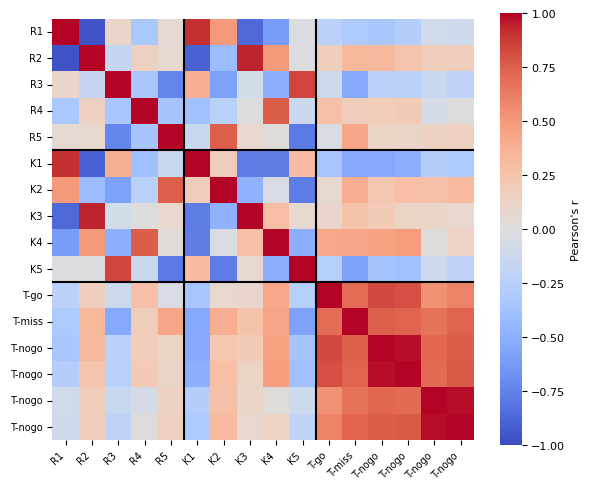

In [7]:
tick_labels = []
block_sizes = []
for label in clusters:
    centroids = clusters[label]['centroids']
    n = centroids.shape[0]
    block_sizes.append(n)
    if 'contrasts' in label:
        tick_labels += [f'T-{cn[:4]}' for cn in clusters[label]['condition_names']]
    elif 'REST' in label:
        tick_labels += [f'R{i+1}' for i in range(n)]
    else:
        tick_labels += [f'K{i+1}' for i in range(n)]

all_centroids = np.vstack([clusters[l]['centroids'] for l in clusters])
n_total = all_centroids.shape[0]

corr_mat = np.zeros((n_total, n_total))
for i in range(n_total):
    for j in range(n_total):
        mask = ~(np.isnan(all_centroids[i]) | np.isnan(all_centroids[j]))
        corr_mat[i, j] = sp.stats.pearsonr(all_centroids[i, mask], all_centroids[j, mask])[0]

fig, ax = plt.subplots(1, 1, figsize=(6, 6))
sns.heatmap(
    corr_mat, ax=ax, square=True,
    xticklabels=tick_labels, yticklabels=tick_labels,
    cmap='coolwarm', center=0, vmin=-1, vmax=1,
    cbar_kws={'shrink': 0.75, 'label': "Pearson's r"}
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=7)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=7)

# block separator lines
cum = 0
for bs in block_sizes[:-1]:
    cum += bs
    ax.axhline(cum, color='k', linewidth=1.5)
    ax.axvline(cum, color='k', linewidth=1.5)

fig.tight_layout()
fig.savefig(os.path.join(out_dir, 'brain_state_correlation_combined.png'), dpi=600, bbox_inches='tight', pad_inches=0.01)
plt.show()


# Correspondence with canonical Yeo systems

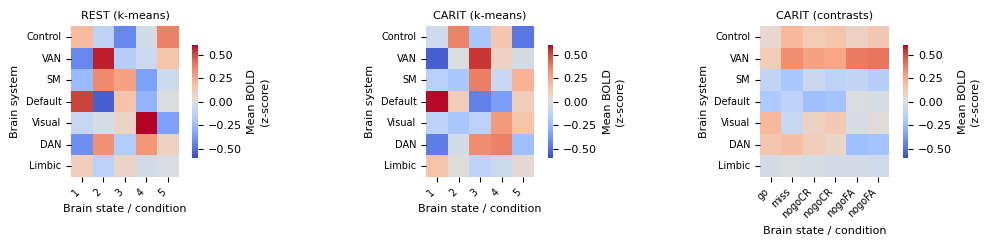

In [8]:
yeo_systems        = ['Cont', 'SalVentAttn', 'SomMot', 'Default', 'Vis', 'DorsAttn', 'Limbic']
yeo_systems_labels = ['Control', 'VAN', 'SM', 'Default', 'Visual', 'DAN', 'Limbic']
n_systems = len(yeo_systems)

n_panels = len(clusters)
fig, axes = plt.subplots(1, n_panels, figsize=(3.5 * n_panels, 2.5))

for ax, label in zip(axes, clusters):
    centroids = clusters[label]['centroids']
    n_states  = centroids.shape[0]
    mean_activity = np.zeros((n_systems, n_states))

    for sys_idx, system in enumerate(yeo_systems):
        mask = get_schaefer_system_mask(parc_centroids.index, system=system)
        for state_idx in range(n_states):
            mean_activity[sys_idx, state_idx] = np.nanmean(centroids[state_idx, mask])

    if 'contrasts' in label:
        x_labels = [cn[:6] for cn in clusters[label]['condition_names']]
    else:
        x_labels = [str(i + 1) for i in range(n_states)]

    sns.heatmap(
        mean_activity, ax=ax, square=True,
        cmap='coolwarm', center=0, vmin=-0.6, vmax=0.6,
        cbar_kws={'shrink': 0.75, 'label': 'Mean BOLD\n(z-score)'}
    )
    ax.set_title(label, fontsize=8)
    ax.set_xlabel('Brain state / condition')
    ax.set_ylabel('Brain system')
    ax.set_xticklabels(x_labels, rotation=45, ha='right', fontsize=7)
    ax.set_yticklabels(yeo_systems_labels, rotation=0, fontsize=7)

fig.tight_layout()
fig.savefig(os.path.join(out_dir, 'brain_state_system_mapping.png'), dpi=600, bbox_inches='tight', pad_inches=0.01)
plt.show()


# Aggregate clusters for control energy

In [9]:
# Stack all three state sets: REST k-means + task k-means + task contrasts
c_rest    = clusters['REST (k-means)']['centroids']
c_task_km = clusters[f'{task_label} (k-means)']['centroids']
c_task_ct = clusters[f'{task_label} (contrasts)']['centroids']

combined_centroids = np.vstack([c_rest, c_task_km, c_task_ct])
n_combined = combined_centroids.shape[0]
print('Combined centroids shape:', combined_centroids.shape)
print(f'  REST k-means:         {c_rest.shape[0]} states')
print(f'  {task_label} k-means:          {c_task_km.shape[0]} states')
print(f'  {task_label} contrasts:        {c_task_ct.shape[0]} conditions')

combined_clusters = {'centroids': combined_centroids}
combined_prefix = f'{dataset}_{seg}_REST-{task_label}-kmeans-contrasts'
combined_fname  = f'{combined_prefix}_fmri_clusters_k-{n_combined}.npy'
combined_fpath  = os.path.join(nct_dir, combined_fname)
np.save(combined_fpath, combined_clusters)
print('\nSaved:', combined_fpath)


Combined centroids shape: (16, 400)
  REST k-means:         5 states
  CARIT k-means:          5 states
  CARIT contrasts:        6 conditions

Saved: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales/data/nct/HCP-D/HCP-D_Schaefer4007_REST-CARIT-kmeans-contrasts_fmri_clusters_k-16.npy


# Structural connectomes

In [10]:
from src.timescales import Timescales
from src.notebook import _load_hcpya_connectivity, _load_hcpd_connectivity

# ── Get derivdata_dir from existing infrastructure ────────────────────────────
_processor = Timescales(dataset=dataset, timeseries_data=None, verbose=False)
derivdata_dir = _processor.derivdata_dir

# ── Subject IDs from the REST timeseries file keys ────────────────────────────
_ts = np.load(
    os.path.join(projdir, 'data', 'timeseries', dataset,
                 f'{dataset}_{seg}_task-{rest_task}_data-ts.npy'),
    allow_pickle=True
).item()
subject_ids = sorted(set(
    k.split('_')[0].replace('sub-', '')
    for k in _ts.keys()
))
print(f'N subjects: {len(subject_ids)}')

# ── Load connectivity ─────────────────────────────────────────────────────────
# adjacency_matrices : (n_regions, n_regions, n_subjects)  — raw streamcount, volume-normalised
# adjacency_mean     : (n_regions, n_regions)              — group-consistency thresholded mean
# strength           : (n_regions, n_subjects)             — log node strength per subject
if dataset == 'HCP-YA':
    adjacency_matrices, adjacency_mean, strength = _load_hcpya_connectivity(
        derivdata_dir, subject_ids, n_parcels
    )
elif dataset == 'HCP-D':
    adjacency_matrices, adjacency_mean, strength = _load_hcpd_connectivity(
        derivdata_dir, subject_ids, n_parcels
    )

# ── Filter subjects with missing connectivity data ────────────────────────────
valid_mask = ~np.all(np.isnan(adjacency_matrices), axis=(0, 1))
n_removed = int((~valid_mask).sum())
if n_removed > 0:
    print(f'Removing {n_removed} subjects with all-NaN adjacency matrices')
    adjacency_matrices = adjacency_matrices[:, :, valid_mask]
    strength           = strength[:, valid_mask]
    subject_ids        = [s for s, v in zip(subject_ids, valid_mask) if v]

print(f'adjacency_matrices: {adjacency_matrices.shape}')
print(f'adjacency_mean:     {adjacency_mean.shape}')
print(f'strength:           {strength.shape}')
print(f'N subjects (conn):  {len(subject_ids)}')


N subjects: 552
Loading connectivity data...
	sub-HCD0403224V1MR not found
	sub-HCD0904650V1MR not found
	sub-HCD1181843V1MR not found
	sub-HCD1227740V1MR not found
	sub-HCD1350638V1MR not found


/home/lindenmp/anaconda3/envs/intrinsic_neural_timescales/lib/python3.11/site-packages/src/notebook.py:266: RuntimeWarning: divide by zero encountered in log
  strength[:, i] = np.log(adjacency_norm.sum(axis=0))


	sub-HCD2863975V1MR not found
Removing 6 subjects with all-NaN adjacency matrices
adjacency_matrices: (400, 400, 546)
adjacency_mean:     (400, 400)
strength:           (400, 546)
N subjects (conn):  546


In [11]:
np.save(os.path.join(nct_dir, f'{dataset}_{seg}_adjacency_matrices.npy'), adjacency_matrices)
np.save(os.path.join(nct_dir, f'{dataset}_{seg}_adjacency_mean.npy'), adjacency_mean)
with open(os.path.join(nct_dir, f'{dataset}_{seg}_adjacency_subject_ids.txt'), 'w') as f:
    f.write('\n'.join(subject_ids))
print('Saved adjacency_matrices:', adjacency_matrices.shape)
print('Saved adjacency_mean:    ', adjacency_mean.shape)
print('Saved subject_ids:       ', len(subject_ids))


Saved adjacency_matrices: (400, 400, 546)
Saved adjacency_mean:     (400, 400)
Saved subject_ids:        546
